## Slides 1–4 · Introduction & workflow
**Live demo:** bad data → bad statistics. Real-world context: banking transactions.

# Workshop 2 — Data Analysis & Preparation

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid") # Sets all Seaborn and matplotlib plots to whitegrid style



transactions = pd.DataFrame({"amount_dzd": [600, 1500, 2500, 900, 250000],
                             "merchant": ["shop", "fuel", "shop", "food", "shop"]}) # dataframe object speciale

# 1 Columns of a Pandas dataFrame => Pandas Series (eq to Numpy array)
amounts = transactions["amount_dzd"]

print(type(amounts))

amounts = amounts.to_numpy() # Switch to Numpy arrays for convience

print(type(amounts))


<class 'pandas.core.series.Series'>
<class 'numpy.ndarray'>


In [ ]:
print("Mean:", np.mean(amounts), "Median:", np.median(amounts))
transactions

Mean: 51100.0 Median: 1500.0


,amount_dzd,merchant
0,600,shop
1,1500,fuel
2,2500,shop
3,900,food
4,250000,shop


## Slide 5 · Our running example: Titanic
The six rows below reproduce the **illustrative sample from the original slide**, not the full Titanic dataset.

In [ ]:
titanic_sample = pd.DataFrame({
    "Age": [22, 38, np.nan, 35, 28, 45],
    "Sex": ["male", "female", "female", "Male", "male", "female"],
    "Pclass": [3, 1, 3, 1, 3, 1],
    "Fare": [7.25, 71.28, 7.92, 53.10, 8.05, 512.33],
    "Survived": [0, 1, 1, 1, 0, 1]
})
titanic_sample

,Age,Sex,Pclass,Fare,Survived
0,22.0,male,3,7.25,0
1,38.0,female,1,71.28,1
2,NaN,female,3,7.92,1
3,35.0,Male,1,53.10,1
4,28.0,male,3,8.05,0
5,45.0,female,1,512.33,1


## Slides 6–8 · Mean, median, mode, spread, distributions
**Real-world question:** Does the mean describe a typical apartment price?

In [ ]:
# apartment prices in millions of DZD
prices = np.array([10, 11, 12, 13, 54])
print("Mean:", np.mean(prices), "Median:", np.median(prices))
ages = np.array([22, 25, 25, 30, 95])
values, counts = np.unique(ages, return_counts=True)
print(values)
print(counts)
print("Mode:", values[np.argmax(counts)])
print("Std:", np.std(prices), "Range:", np.ptp(prices))
print("Q1, Q3:", np.percentile(prices, [25, 75]))

Mean: 20.0 Median: 12.0
[22 25 30 95]
[1 2 1 1]
Mode: 25
Std: 17.029386365926403 Range: 44
Q1, Q3: [11. 13.]


In [ ]:
# 150 real iris flower observations, supplied with scikit-learn
from sklearn.datasets import load_iris


iris_data = load_iris(as_frame=True) # The datasets come as Pandas DataFrames
iris = iris_data.frame.copy()
iris = iris.rename(columns={"target": "species_id"})


print(iris)
print("Iris dataset:", iris.shape)



     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                  5.1               3.5                1.4               0.2   
1                  4.9               3.0                1.4               0.2   
2                  4.7               3.2                1.3               0.2   
3                  4.6               3.1                1.5               0.2   
4                  5.0               3.6                1.4               0.2   
..                 ...               ...                ...               ...   
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
149                5.9               3.0                5.1               1.8   

     species_id  
0        

In [ ]:
petals = iris["petal length (cm)"] # 1 Columns of a Pandas dataFrame => Pandas Series (eq to Numpy array)

print(type(petals))

petals = petals.to_numpy() # Switch to Numpy arrays for convience

print(type(petals))

<class 'pandas.core.series.Series'>
<class 'numpy.ndarray'>


Mean / Median / Std / IQR: 3.7580000000000005 4.35 1.759404065775303 3.4999999999999996


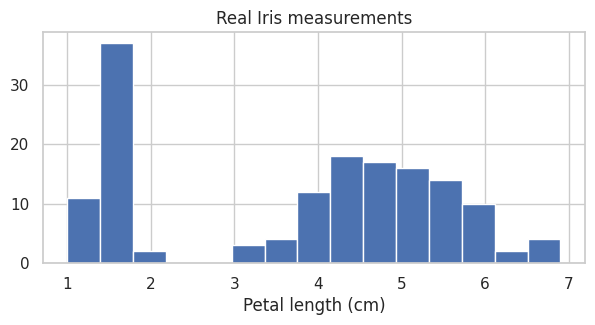

In [ ]:
print("Mean / Median / Std / IQR:", np.mean(petals), np.median(petals),
      np.std(petals), np.diff(np.percentile(petals, [25, 75]))[0])
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(petals, bins=15)
ax.set(xlabel="Petal length (cm)", title="Real Iris measurements")
plt.show()

## Slides 9–10 · Correlation and heatmaps
Compare measurements from the **real Wisconsin diagnostic dataset**. Correlation does not establish causation.

In [ ]:
# 569 Wisconsin Diagnostic Breast Cancer measurement records
from sklearn.datasets import load_breast_cancer


cancer_data = load_breast_cancer(as_frame=True)
medical = cancer_data.frame.rename(columns={"target": "label"}).copy()
cols = ["mean radius", "mean perimeter", "mean area", "mean texture"]

correlation = medical[cols]

print(correlation.corr())


                mean radius  mean perimeter  mean area  mean texture
mean radius        1.000000        0.997855   0.987357      0.323782
mean perimeter     0.997855        1.000000   0.986507      0.329533
mean area          0.987357        0.986507   1.000000      0.321086
mean texture       0.323782        0.329533   0.321086      1.000000


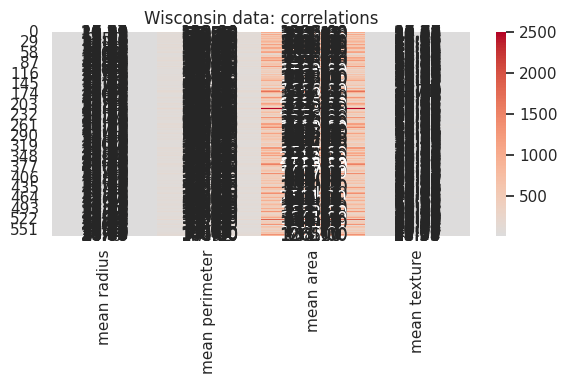

In [ ]:
plt.figure(figsize=(6, 4))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Wisconsin data: correlations")
plt.tight_layout(); plt.show()

## Slide 11 · Statistics cheat sheet
NumPy for numeric arrays; pandas for DataFrame summaries.

In [ ]:
print("Mean:", np.mean(petals), "Median:", np.median(petals))
print("Std:", np.std(petals), "IQR:", np.percentile(petals, 75) - np.percentile(petals, 25))
print("Skewness:", iris["petal length (cm)"].skew())
iris.describe()

Mean: 3.7580000000000005 Median: 4.35
Std: 1.759404065775303 IQR: 3.4999999999999996
Skewness: -0.27488417975101276


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species_id
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


## Slides 12–14 · Exploratory Data Analysis (EDA)
Inspect rows, columns, types, categories, and summary statistics.

In [ ]:
display(iris.head())
print("Shape:", iris.shape)
iris.info()
print("Types:\n", iris.dtypes)
print("Species counts:\n", iris["species_id"].value_counts())
print("Unique values:\n", iris.nunique())
display(iris.describe())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species_id
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Shape: (150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species_id         150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
Types:
 sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species_id             int64
dtype: object
Species counts:
 species_id
0    50
1    50
2    50
Name: count, dtype: int64
Unique values:
 sepal length (cm)    35
sepal width (cm)     23
petal length (cm)    43
petal width (cm)     22
species_id            3
dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species_id
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


## Slide 15 · Missing values
For this exercise we **deliberately introduce** missing values into real medical measurements.

In [ ]:

dirty = medical[["mean radius", "mean texture", "mean area", "label"]].copy()

dirty.loc[::17, "mean radius"] = np.nan  # introduce missing values in every 17th row in "mean radius" column
print(dirty["mean radius"][17])
print("Missing counts:\n", dirty.isna().sum())
print("Missing %:\n", (dirty.isna().mean() * 100).round(1))

nan
Missing counts:
 mean radius     34
mean texture     0
mean area        0
label            0
dtype: int64
Missing %:
 mean radius     6.0
mean texture    0.0
mean area       0.0
label           0.0
dtype: float64


## Slides 16–19 · Histograms, boxplots, bar plots, scatter plots
Use real Iris and medical measurements.

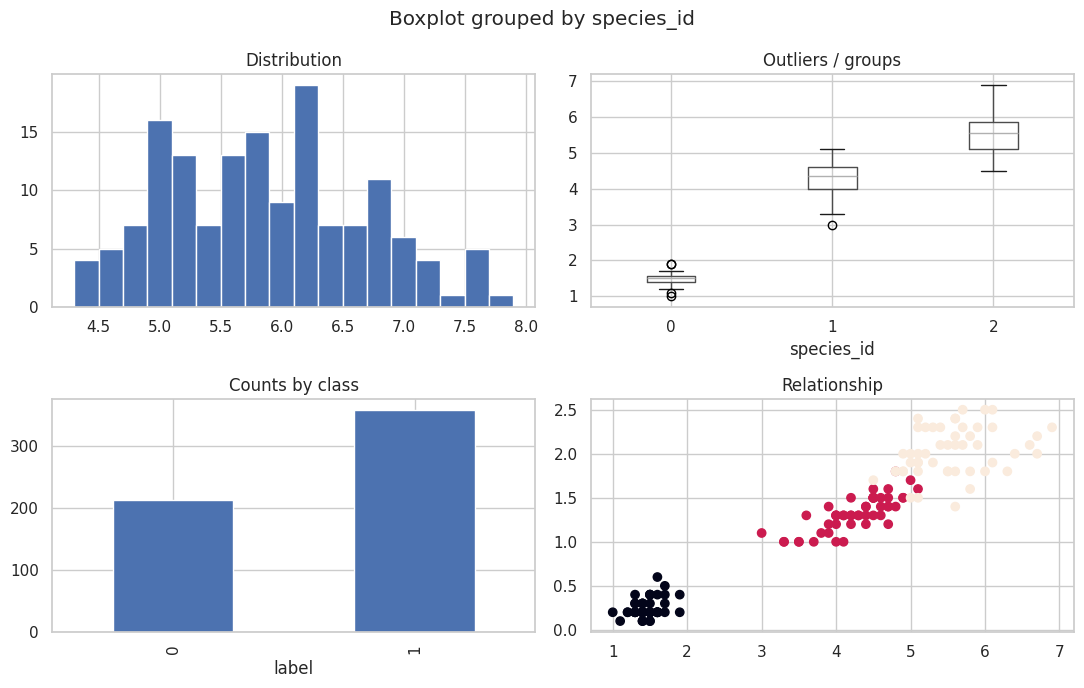

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

axes[0,0].hist(iris["sepal length (cm)"].to_numpy(), bins=18)
iris.boxplot(column="petal length (cm)", by="species_id", ax=axes[0,1])
medical["label"].value_counts().sort_index().plot.bar(ax=axes[1,0])
axes[1,1].scatter(iris["petal length (cm)"], iris["petal width (cm)"], c=iris["species_id"])

for ax, title in zip(axes.flat,["Distribution", "Outliers / groups", "Counts by class", "Relationship"]): ax.set_title(title)
plt.tight_layout();
plt.show()

## Slides 20–21 · Drop or impute?
Compare how much data remains, then fill missing values with a training example median.

In [ ]:

print("Rows originally:", len(dirty))
print( dirty.dropna(axis=1).columns.tolist())
print("Rows after dropna:", len(dirty.dropna()))
print("Columns after dropna(axis=1):", dirty.dropna(axis=1).columns.tolist())
clean = dirty.copy()
radius = clean["mean radius"].to_numpy()  # NumPy array
median_radius = np.nanmedian(radius)
clean["mean radius"] = clean["mean radius"].fillna(median_radius)
print("Median used:", median_radius)
print("Missing remaining:", clean.isna().sum().sum())

Rows originally: 569
['mean texture', 'mean area', 'label']
Rows after dropna: 535
Columns after dropna(axis=1): ['mean texture', 'mean area', 'label']
Median used: 13.34
Missing remaining: 0


## Slide 22 · Duplicates, inconsistent labels, data types
These errors are **deliberately created**, not errors in the real Iris data.

In [ ]:
messy = pd.DataFrame({"Age": ["22", "38", "22", "35", "22"],
                      "Sex": [" Male ", "female", " Male ", "MALE", " Male "]})
print("Before:"); display(messy)
messy["Age"] = pd.to_numeric(messy["Age"])
messy["Sex"] = messy["Sex"].str.strip().str.lower()
messy = messy.drop_duplicates()
print("After:"); display(messy)

Before:


,Age,Sex
0,22,Male
1,38,female
2,22,Male
3,35,MALE
4,22,Male


After:


,Age,Sex
0,22,male
1,38,female
3,35,male


## Slides 23–24 · Outliers: detect and decide
An unusually large transaction may be important for fraud detection; **do not automatically delete it**.

IQR boundaries: 5.579999999999999 21.9
Number of potential outliers: 14
Transaction amounts: [   600   1500   2500    900 250000]
High amount flagged: [False False False False  True]


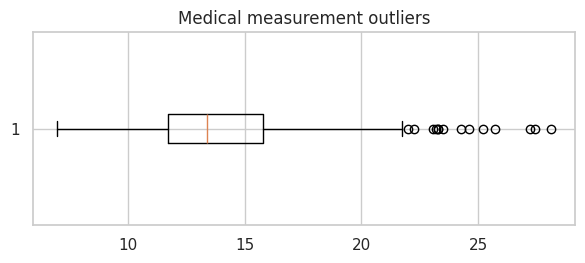

In [ ]:
radii = medical["mean radius"].to_numpy()
q1, q3 = np.percentile(radii, [25, 75]); iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print("IQR boundaries:", lower, upper)
print("Number of potential outliers:", np.sum((radii < lower) | (radii > upper)))
print("Transaction amounts:", amounts)
print("High amount flagged:", amounts > 100000)
plt.figure(figsize=(7, 2.5)); plt.boxplot(radii, vert=False); plt.title("Medical measurement outliers"); plt.show()

## Slide 25 · Feature engineering
**Delivery-time example:** extract rush-hour and weekend indicators from timestamps (hypothetical orders).

In [ ]:
orders = pd.DataFrame({"ordered_at": ["2026-11-06 18:30", "2026-11-07 11:00", "2026-11-09 08:15"],
                       "distance_km": [4.2, 2.5, 7.1], "rain": [1, 0, 0]})
orders["ordered_at"] = pd.to_datetime(orders["ordered_at"])
orders["hour"] = orders["ordered_at"].dt.hour
orders["weekend"] = orders["ordered_at"].dt.dayofweek >= 5
orders["rush_hour"] = orders["hour"].between(17, 19)
orders

,ordered_at,distance_km,rain,hour,weekend,rush_hour
0,2026-11-06 18:30:00,4.2,1,18,False,True
1,2026-11-07 11:00:00,2.5,0,11,True,False
2,2026-11-09 08:15:00,7.1,0,8,False,False


## Slide 26 · Encoding categorical features
Use pandas DataFrames for one-hot encoding.

In [ ]:
flowers = iris.copy()
flowers["species"] = flowers["species_id"].map({0:"setosa",1:"versicolor",2:"virginica"})
encoded = pd.get_dummies(flowers[["species"]], dtype=int)
display(encoded.head())

,species_setosa,species_versicolor,species_virginica
0,1,0,0
1,1,0,0
2,1,0,0
3,1,0,0
4,1,0,0


## Slide 27 · Feature scaling
Use NumPy arrays to demonstrate standardization and min-max scaling.

In [16]:
lengths = iris["sepal length (cm)"].to_numpy()
standardized = (lengths - np.mean(lengths)) / np.std(lengths)
minmax = (lengths - np.min(lengths)) / (np.max(lengths) - np.min(lengths))
print("Original:", lengths[:5])
print("Standardized:", np.round(standardized[:5], 2))
print("Min-max:", np.round(minmax[:5], 2))

Original: [5.1 4.9 4.7 4.6 5. ]
Standardized: [-0.9  -1.14 -1.39 -1.51 -1.02]
Min-max: [0.22 0.17 0.11 0.08 0.19]


## Slide 28 · Log transforms and binning
Transform skewed real measurements; bin ages from the original slide example.

In [ ]:
areas = medical["mean area"].to_numpy()
print("Original area range:", np.min(areas), np.max(areas))
print("Log(area) range:", np.min(np.log1p(areas)), np.max(np.log1p(areas)))
print("Age groups:")
display(pd.cut(titanic_sample["Age"], bins=[0, 18, 40, 100], labels=["child", "adult", "older"]))

Original area range: 143.5 2501.0
Log(area) range: 4.973279507552487 7.824845691026857
Age groups:


,Age
0,adult
1,adult
2,NaN
3,adult
4,adult
5,older


## Slide 29 · Data leakage
Fit preprocessing statistics on **training data only**. The example below uses real Iris measurements.

In [ ]:
from sklearn.model_selection import train_test_split
X = iris[["sepal length (cm)", "petal length (cm)"]].to_numpy()
train_X, test_X = train_test_split(X, test_size=0.25, random_state=42)
train_mean, train_std = np.mean(train_X, axis=0), np.std(train_X, axis=0)
train_scaled = (train_X - train_mean) / train_std
test_scaled = (test_X - train_mean) / train_std  # reuse train statistics
print("Train mean after scaling:", np.round(train_scaled.mean(axis=0), 3))
print("Test shape:", test_scaled.shape)

Train mean after scaling: [ 0. -0.]
Test shape: (38, 2)


In [ ]:


titanic = titanic_sample.copy()
print("Using the six-row sample from slide 5")
display(titanic.head())
print("Missing values:\n", titanic.isna().sum())
print("Numerical summary:\n", titanic.describe())

Using the six-row sample from slide 5


,Age,Sex,Pclass,Fare,Survived
0,22.0,male,3,7.25,0
1,38.0,female,1,71.28,1
2,NaN,female,3,7.92,1
3,35.0,Male,1,53.10,1
4,28.0,male,3,8.05,0


Missing values:
 Age         1
Sex         0
Pclass      0
Fare        0
Survived    0
dtype: int64
Numerical summary:
              Age    Pclass        Fare  Survived
count   5.000000  6.000000    6.000000  6.000000
mean   33.600000  2.000000  109.988333  0.666667
std     8.905055  1.095445  198.986416  0.516398
min    22.000000  1.000000    7.250000  0.000000
25%    28.000000  1.000000    7.952500  0.250000
50%    35.000000  2.000000   30.575000  1.000000
75%    38.000000  3.000000   66.735000  1.000000
max    45.000000  3.000000  512.330000  1.000000


Survival rate by class:
Pclass
1    1.000000
3    0.333333
Name: Survived, dtype: float64


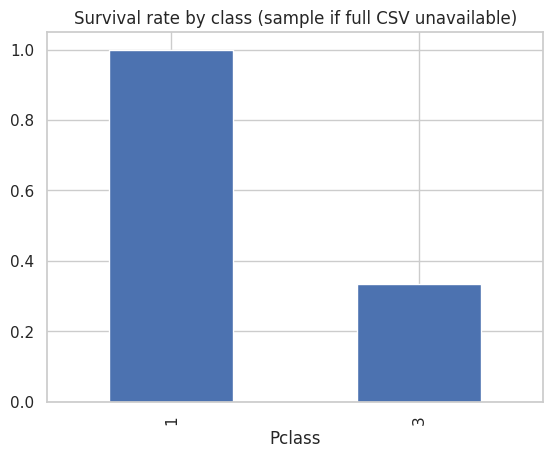

In [ ]:
# YOUR TURN: clean Age, normalize Sex, then compare survival by class.
practice = titanic.copy()
practice["Age"] = practice["Age"].fillna(practice["Age"].median())
practice["Sex"] = practice["Sex"].str.strip().str.lower()
print("Survival rate by class:")
print(practice.groupby("Pclass")["Survived"].mean())
practice.groupby("Pclass")["Survived"].mean().plot.bar()
plt.title("Survival rate by class (sample if full CSV unavailable)")
plt.show()

## Real datasets
Choose **Iris**, **medical measurements**, or **handwritten digits**. All three load from `sklearn.datasets` with no CSV downloads.


Dataset shape: (1797, 64)
One image shape: (8, 8)


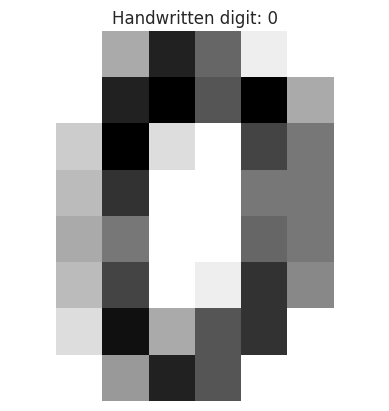

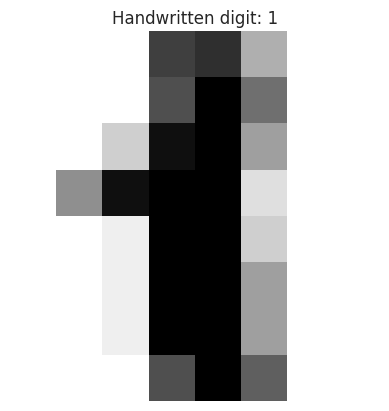

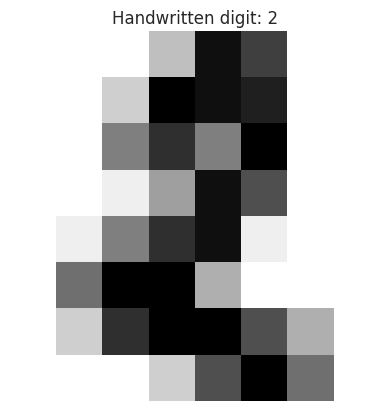

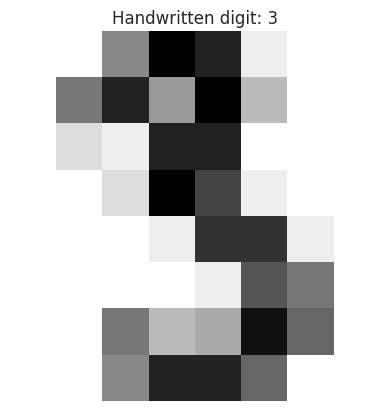

In [ ]:
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt
import numpy as np

digits = load_digits()

print("Dataset shape:", digits.data.shape)
print("One image shape:", digits.images[0].shape)

for digit in range(4) :

    plt.imshow(digits.images[digit], cmap="gray_r")
    plt.title(f"Handwritten digit: {digits.target[digit]}")
    plt.axis("off")
    plt.show()